In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import re

RANDOM_SEED = 42

In [2]:
data = pd.read_csv("fake_reviews.csv")
data.head()

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB


In [4]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
category    0
rating      0
label       0
text_       0
dtype: int64


In [5]:
print("Label distribution:")
print(data['label'].value_counts())

Label distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64


In [6]:
print("Unique labels:", data['label'].unique())

Unique labels: ['CG' 'OR']


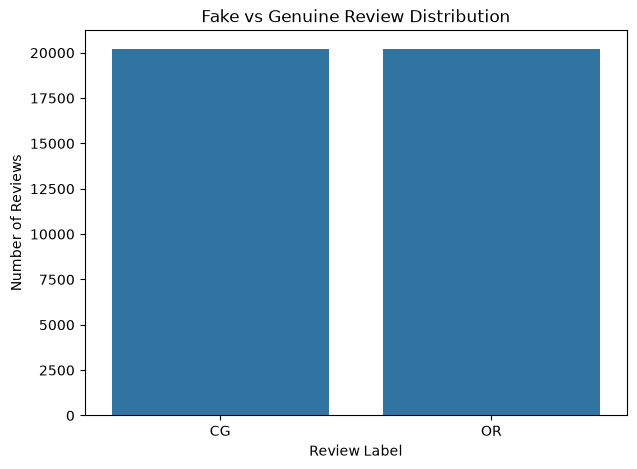

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(x='label', data=data)

plt.title("Fake vs Genuine Review Distribution")
plt.xlabel("Review Label")
plt.ylabel("Number of Reviews")

plt.show()

In [8]:
print("CG Reviews:")
display(data[data['label'] == 'CG'][['rating', 'text_']].head(3))

print("\nOR Reviews:")
display(data[data['label'] == 'OR'][['rating', 'text_']].head(3))

CG Reviews:


,rating,text_
0,5.0,"Love this! Well made, sturdy, and very comfor..."
1,5.0,"love it, a great upgrade from the original. I..."
2,5.0,This pillow saved my back. I love the look and...



OR Reviews:


,rating,text_
55,5.0,"These are just perfect, exactly what I was loo..."
56,5.0,Such a great purchase can't beat it for the price
57,5.0,What can you say--- cheap and it works as inte...


In [9]:
# Text preprocessing function

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# Apply preprocessing
data['clean_text'] = data['text_'].apply(clean_text)

# Display original and cleaned reviews
data[['text_', 'clean_text']].head()

,text_,clean_text
0,"Love this! Well made, sturdy, and very comfor...",love this well made sturdy and very comfortabl...
1,"love it, a great upgrade from the original. I...",love it a great upgrade from the original ive ...
2,This pillow saved my back. I love the look and...,this pillow saved my back i love the look and ...
3,"Missing information on how to use it, but it i...",missing information on how to use it but it is...
4,Very nice set. Good quality. We have had the s...,very nice set good quality we have had the set...


In [10]:
data['target'] = data['label'].map({
    'CG': 'Fake',
    'OR': 'Genuine'
})

print(data[['label', 'target']].drop_duplicates())

   label   target
0     CG     Fake
55    OR  Genuine


In [11]:
print(data['target'].value_counts())

target
Fake       20216
Genuine    20216
Name: count, dtype: int64


In [12]:
# Define input and target

X = data['clean_text']
y = data['target']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (40432,)
y shape: (40432,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 32345
Testing samples: 8087


In [14]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (32345, 5000)
Testing TF-IDF shape: (8087, 5000)


In [15]:
# Train Logistic Regression model

model_lr = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_SEED
)

model_lr.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_lr = model_lr.predict(X_test_tfidf)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

Logistic Regression Accuracy: 0.8615061209348337


In [16]:
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

Classification Report:
              precision    recall  f1-score   support

        Fake       0.87      0.85      0.86      4044
     Genuine       0.86      0.87      0.86      4043

    accuracy                           0.86      8087
   macro avg       0.86      0.86      0.86      8087
weighted avg       0.86      0.86      0.86      8087



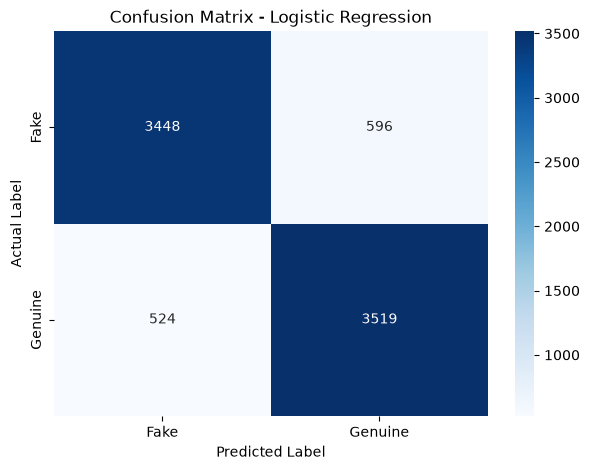

In [17]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Genuine'],
    yticklabels=['Fake', 'Genuine']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [18]:
# Train Naive Bayes model

model_nb = MultinomialNB()

model_nb.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb = model_nb.predict(X_test_tfidf)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb)

Naive Bayes Accuracy: 0.8453072832941758


In [19]:
print("Classification Report - Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

Classification Report - Naive Bayes:
              precision    recall  f1-score   support

        Fake       0.83      0.87      0.85      4044
     Genuine       0.86      0.82      0.84      4043

    accuracy                           0.85      8087
   macro avg       0.85      0.85      0.85      8087
weighted avg       0.85      0.85      0.85      8087



In [20]:
# Train Random Forest model

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

model_rf.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_rf = model_rf.predict(X_test_tfidf)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.835538518610115


In [21]:
print("Classification Report - Random Forest:")
print(classification_report(y_test, y_pred_rf))


Classification Report - Random Forest:
              precision    recall  f1-score   support

        Fake       0.82      0.86      0.84      4044
     Genuine       0.86      0.81      0.83      4043

    accuracy                           0.84      8087
   macro avg       0.84      0.84      0.84      8087
weighted avg       0.84      0.84      0.84      8087



In [22]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_nb,
        accuracy_rf
    ]
})

print(results)

                 Model  Accuracy
0  Logistic Regression  0.861506
1          Naive Bayes  0.845307
2        Random Forest  0.835539


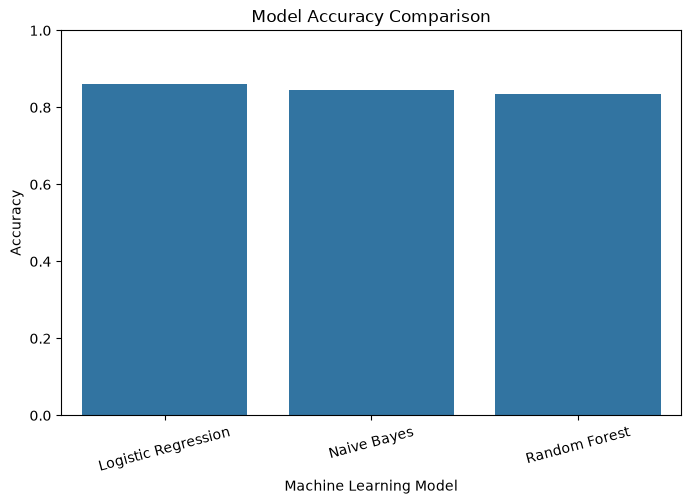

In [23]:
# Visualize model accuracy

plt.figure(figsize=(8, 5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [24]:
# Function to predict a new review

def predict_review(review):
    # Clean the review
    cleaned_review = clean_text(review)
    
    # Convert text to TF-IDF
    review_tfidf = vectorizer.transform([cleaned_review])
    
    # Predict
    prediction = model_lr.predict(review_tfidf)[0]
    
    return prediction

In [25]:
# Test with a new review

review = input("Enter a product review: ")

result = predict_review(review)

print("\nPrediction:", result)

Enter a product review:  The product is excellent and the quality is very good. I have been using it for two months and it works perfectly.



Prediction: Fake


In [26]:
# Predict review with probability

def predict_review_with_probability(review):
    cleaned_review = clean_text(review)
    
    review_tfidf = vectorizer.transform([cleaned_review])
    
    prediction = model_lr.predict(review_tfidf)[0]
    probabilities = model_lr.predict_proba(review_tfidf)[0]
    
    # Get probability of predicted class
    confidence = max(probabilities) * 100
    
    return prediction, confidence

In [27]:
# Test the prediction

review = input("Enter a product review: ")

prediction, confidence = predict_review_with_probability(review)

print("\nPrediction:", prediction)
print("Confidence: {:.2f}%".format(confidence))

Enter a product review:   Amazing product, very useful and good quality.



Prediction: Fake
Confidence: 74.13%


In [28]:
# Calculate evaluation metrics for all models

from sklearn.metrics import precision_score, recall_score, f1_score

model_names = [
    "Logistic Regression",
    "Naive Bayes",
    "Random Forest"
]

predictions = [
    y_pred_lr,
    y_pred_nb,
    y_pred_rf
]

comparison = []

for name, pred in zip(model_names, predictions):
    comparison.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, pos_label='Fake'),
        recall_score(y_test, pred, pos_label='Fake'),
        f1_score(y_test, pred, pos_label='Fake')
    ])

results_detailed = pd.DataFrame(
    comparison,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

results_detailed

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.861506,0.868077,0.852621,0.860279
1,Naive Bayes,0.845307,0.830064,0.868447,0.848822
2,Random Forest,0.835539,0.818097,0.863007,0.839952
